# Notebook 3 – Association Rules

## 1. Introdução

### **Grupo G15 – Teammates**
- **Nuno Miguel Rodrigues da Silva (a25417)**  
- **Hugo Francisco Pereira Azevedo (a25431)**  
- **Tiago André Alves Castro (a25434)**  
- **Gonçalo Edi Pinto Homem de Figueiredo (a26747)**  
- **João Miguel Santos Silva Campos Cunha (a23519)**  

Este notebook corresponde ao **Notebook 3 – Association Rules** do Projeto 02 da unidade curricular de **Inteligência Artificial**.

O objetivo deste trabalho é aplicar técnicas de **Regras de Associação** (*Association Rule Mining*) ao mesmo dataset FIFA utilizado nos notebooks anteriores, de forma a identificar **padrões frequentes** e relações relevantes entre atributos dos jogadores.

Mais concretamente, este notebook inclui:
- Definição do **objetivo de negócio** associado às regras de associação;  
- Descrição do **dataset** utilizado (mesmo dataset dos Notebooks 1 e 2);  
- **Preparação** dos dados para o algoritmo Apriori (discretização e one-hot encoding);  
- Aplicação do algoritmo **Apriori** para extração de itemsets frequentes;  
- Geração e análise de **regras de associação** com base em suporte, confiança e lift;  
- Discussão dos **resultados intermédios e finais**;  
- **Conclusão** com análise dos resultados e lições aprendidas.


## 2. Dataset

### 2.1 Fonte do Dataset
O dataset utilizado neste projeto é o mesmo dos notebooks anteriores e é proveniente do Kaggle:

- **FIFA Players Ratings Dataset**  
- URL: https://www.kaggle.com/datasets/rishidamarla/fifa-players-ratings  

Tal como nos restantes notebooks, é utilizada a versão **`fifa_cleaned.csv`**, previamente tratada.

---

### 2.2 Metadados do Dataset
Serão analisados:
- Número de jogadores (linhas);  
- Número de atributos (colunas);  
- Tipos de dados;  
- Algumas das primeiras linhas do dataset.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

df = pd.read_csv('fifa_cleaned.csv')
df

,id,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,wage_euro,preferred_foot,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),work_rate,body_type,release_clause_euro,club_team,club_rating,club_position,club_jersey_number,club_join_date,contract_end_year,national_team,national_rating,national_team_position,national_jersey_number,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,freekick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle,GK_diving,GK_handling,GK_kicking,GK_positioning,GK_reflexes,tags,traits,LS,ST,RS,LW,LF,CF,RF,RW,LAM,CAM,RAM,LM,LCM,CM,RCM,RM,LWB,LDM,CDM,RDM,RWB,LB,LCB,CB,RCB,RB
0,158023,L. Messi,Lionel Andrés Messi Cuccittini,1987-06-24,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,565000.0,Left,5,4,4,Medium/ Low,Messi,226500000.0,FC Barcelona,86.0,RW,10.0,2004-07-01,2021,Argentina,82.0,RF,10.0,86,95,70,92,86,97,93,94,89,96,91,86,93,95,95,85,68,72,66,94,48,22,94,94,75,96,33,28,26,6,11,15,14,8,"#Dribbler,#Distance Shooter,#Crosser,#FK Speci...","Finesse Shot,Long Shot Taker (CPU AI Only),Spe...",89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,91+2,85+2,85+2,85+2,91+2,64+2,61+2,61+2,61+2,64+2,59+2,48+2,48+2,48+2,59+2
1,190460,C. Eriksen,Christian Dannemann Eriksen,1992-02-14,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,205000.0,Right,3,5,4,High/ Medium,Lean,133800000.0,Tottenham Hotspur,83.0,LCM,23.0,2013-08-30,2020,Denmark,78.0,CAM,10.0,88,81,52,91,80,84,86,87,89,91,76,73,80,88,81,84,50,92,58,89,46,56,84,91,67,88,59,57,22,9,14,7,7,6,"#Playmaker ,#Crosser,#FK Specialist,#Complete...","Flair,Long Shot Taker (CPU AI Only),Playmaker ...",79+3,79+3,79+3,85+3,84+3,84+3,84+3,85+3,86+3,86+3,86+3,86+3,85+3,85+3,85+3,86+3,71+3,71+3,71+3,71+3,71+3,66+3,57+3,57+3,57+3,66+3
2,195864,P. Pogba,Paul Pogba,1993-03-15,25,190.50,83.9,"CM,CAM",France,88,91,73000000.0,255000.0,Right,4,4,5,High/ Medium,Normal,144200000.0,Manchester United,82.0,LCM,6.0,2016-08-09,2021,France,84.0,RDM,6.0,80,75,75,86,85,87,85,82,90,90,71,79,76,82,66,90,83,88,87,82,78,64,82,88,82,87,63,67,67,5,6,2,4,3,"#Dribbler,#Playmaker ,#Strength,#Complete Mid...","Flair,Long Passer (CPU AI Only),Long Shot Take...",81+3,81+3,81+3,82+3,83+3,83+3,83+3,82+3,84+3,84+3,84+3,83+3,84+3,84+3,84+3,83+3,76+3,77+3,77+3,77+3,76+3,74+3,72+3,72+3,72+3,74+3
3,198219,L. Insigne,Lorenzo Insigne,1991-06-04,27,162.56,59.0,"LW,ST",Italy,88,88,62000000.0,165000.0,Right,3,4,4,High/ Medium,Normal,105400000.0,Napoli,82.0,LS,24.0,2010-07-01,2022,Italy,83.0,LW,10.0,86,77,56,85,74,90,87,77,78,93,94,86,94,83,93,75,53,75,44,84,34,26,83,87,61,83,51,24,22,8,4,14,9,10,"#Speedster,#Dribbler,#Crosser,#Acrobat","Finesse Shot,Long Shot Taker (CPU AI Only),Spe...",78+3,78+3,78+3,86+3,85+3,85+3,85+3,86+3,86+3,86+3,86+3,86+3,78+3,78+3,78+3,86+3,63+3,58+3,58+3,58+3,63+3,58+3,44+3,44+3,44+3,58+3
4,201024,K. Koulibaly,Kalidou Koulibaly,1991-06-20,27,187.96,88.9,CB,Senegal,88,91,60000000.0,135000.0,Right,3,3,2,High/ High,Normal,106500000.0,Napoli,82.0,LCB,26.0,2014-07-01,2021,NaN,NaN,NaN,NaN,30,22,83,68,14,69,28,28,60,63,70,75,50,82,40,55,81,75,94,15,87,88,24,49,33,80,91,88,87,7,11,7,13,5,"#Tackling ,#Tactician ,#Strength,#Complete Def...",Power Header,53+3,53+3,53+3,53+3,54+3,54+3,54+3,53+3,55+3,55+3,55+3,57+3,61+3,61+3,61+3,57+3,73+3,77+3,77+3,77+3,73+3,76+3,85+3,85+3,85+3,76+3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17949,204322,R. McKenzie,Rory McKenzie,1993-10-07,25,175.26,74.

In [2]:
print('Número de linhas:', df.shape[0])
print('Número de colunas:', df.shape[1])

Número de linhas: 17954
Número de colunas: 92


In [3]:
df.describe(include='all')

,id,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,wage_euro,preferred_foot,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),work_rate,body_type,release_clause_euro,club_team,club_rating,club_position,club_jersey_number,club_join_date,contract_end_year,national_team,national_rating,national_team_position,national_jersey_number,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,freekick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle,GK_diving,GK_handling,GK_kicking,GK_positioning,GK_reflexes,tags,traits,LS,ST,RS,LW,LF,CF,RF,RW,LAM,CAM,RAM,LM,LCM,CM,RCM,RM,LWB,LDM,CDM,RDM,RWB,LB,LCB,CB,RCB,RB
count,17954.000000,17954,17954,17954,17954.000000,17954.000000,17954.000000,17954,17954,17954.000000,17954.000000,1.769900e+04,17708.000000,17954,17954.000000,17954.000000,17954.000000,17954,17954,1.611700e+04,17940,17940.000000,17940,17940.000000,16018,17593,857,857.000000,857,857.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,1417,8137,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889,15889
unique,NaN,16995,17898,6156,NaN,NaN,NaN,890,160,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,9,10,NaN,687,NaN,29,NaN,1731,24,103,NaN,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,81,1594,95,95,95,105,103,103,103,105,102,102,102,98,92,92,92,98,96,98,98,98,96,97,109,109,109,97
top,NaN,J. Rodríguez,Adama Traoré,1992-02-29,NaN,NaN,NaN,CB,England,NaN,NaN,NaN,NaN,Right,NaN,NaN,NaN,Medium/ Medium,Normal,NaN,Valencia CF,NaN,SUB,NaN,2018-07-01,2021,Denmark,NaN,SUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#Strength,Speed Dribbler (CPU AI Only),61+2,61+2,61+2,63+2,60+2,60+2,60+2,63+2,61+2,61+2,61+2,61+2,58+2,58+2,58+2,61+2,61+2,62+2,62+2,62+2,61+2,64+2,63+2,63+2,63+2,64+2
freq,NaN,8,3,115,NaN,NaN,NaN,2243,1658,NaN,NaN,NaN,NaN,13781,NaN,NaN,NaN,9690,10393,NaN,33,NaN,7870,NaN,1423,4743,23,NaN,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,468,372,689,689,689,730,727,727,727,730,727,727,727,809,753,753,753,809,703,637,637,637,703,655,613,613,613,655
mean,215411.087780,NaN,NaN,NaN,25.565445,174.946921,75.301047,NaN,NaN,66.240169,71.430935,2.479280e+06,9902.134628,NaN,1.111674,2.945695,2.361034,NaN,NaN,4.622522e+06,NaN,69.364158,NaN,20.297324,NaN,NaN,NaN,76.341890,NaN,12.456243,49.697672,45.358249,52.148212,58.566058,42.755208,55.278991,47.101147,42.688092,52.667428,58.223906,64.696224,64.803498,63.377465,61.821878,63.870057,55.319873,64.955219,63.133842,65.158850,46.852456,55.816531,46.657959,49.857302,53.406260,48.357302,58.680183,47.162861,47.733040,45.705915,16.784449,16.556199,16.388660,16.541049,16.874067,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,29758.387106,NaN,NaN,NaN,4.705708,14.029449,7.083684,NaN,NaN,6.963730,6.131339,5.687014e+06,21995.593750,NaN,0.392168,0.663691,0.763223,NaN,NaN,1.129077e+07,NaN,5.091678,NaN,16.464734,NaN,NaN,NaN,4.786667,NaN,8.098157,18.483310,19.640792,17.521819,14.863178,17.802936,19.091876,18.536621,17.565634,15.

## 3. Objetivo de Negócio

O objetivo deste notebook é **descobrir padrões e relações frequentes** entre características dos jogadores FIFA, recorrendo a **regras de associação**.

Em vez de prever uma classe (como no Notebook 1 – Classificação Automática) ou criar grupos de jogadores (como no Notebook 2 – Clustering), aqui pretendemos **identificar combinações de atributos que ocorrem frequentemente em conjunto**.

Este tipo de análise é útil para:
- Identificar perfis típicos de jogadores com determinadas características (ex.: pé preferido, nacionalidade, overall, potencial);  
- Apoiar decisões de **scouting** ao perceber que tipos de jogadores tendem a partilhar certas características;  
- Apoiar análises estratégicas sobre o mercado de jogadores.


## 4. Preparação dos Dados

Nesta secção, os dados são preparados para aplicação do algoritmo de regras de associação (Apriori).  

Os passos principais são:

1. Selecionar um conjunto de **atributos relevantes**;  
2. **Discretizar** variáveis numéricas (ex.: age, overall, potential) em intervalos;  
3. Aplicar **one-hot encoding** para obter uma matriz binária (0/1);  
4. Confirmar o formato final a utilizar no Apriori.


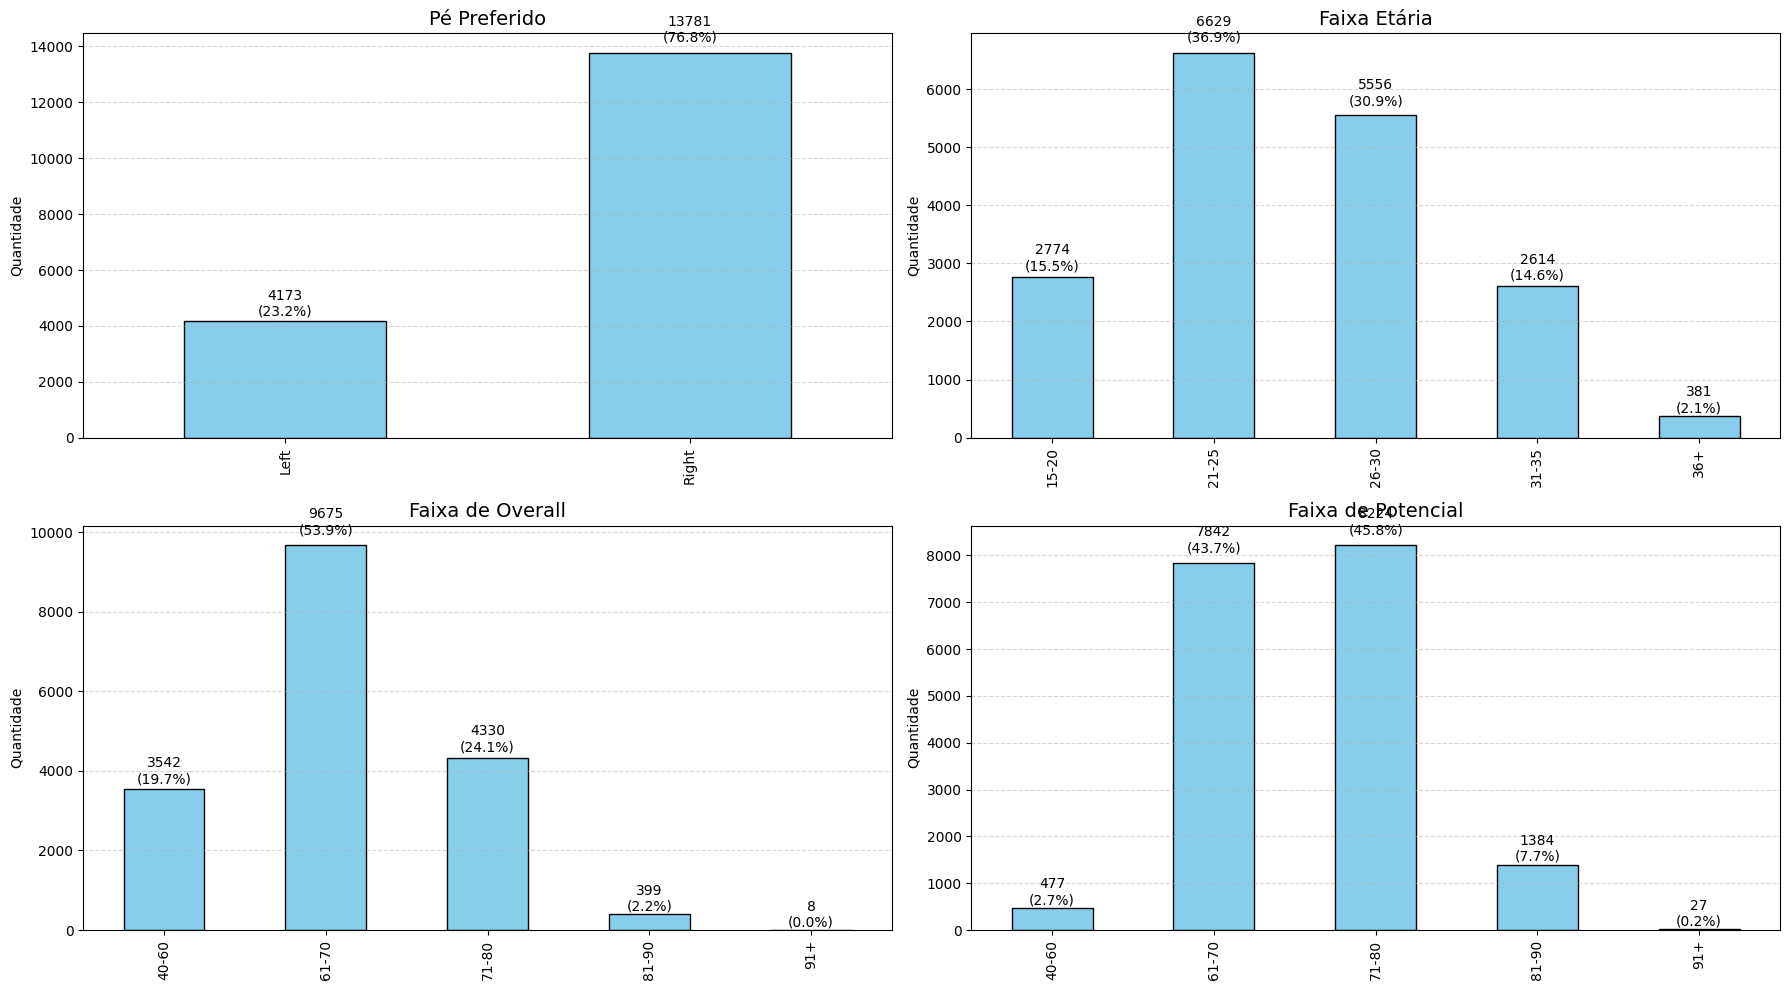

In [6]:
import matplotlib.pyplot as plt

# Lista das colunas categorizadas a mostrar
cols = ['preferred_foot', 'Age_bin', 'Overall_bin', 'Potential_bin']
titles = ['Pé Preferido', 'Faixa Etária', 'Faixa de Overall', 'Faixa de Potencial']

# Configurar subplots (2 linhas x 2 colunas)
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.flatten()

total_rows = len(data)

for ax, col, title in zip(axes, cols, titles):
    
    counts = data[col].value_counts().sort_index()  # contagem ordenada
    
    bars = counts.plot(
        kind='bar',
        ax=ax,
        color='skyblue',
        edgecolor='black'
    )
    
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Quantidade")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Colocar valor + percentagem acima das barras
    for i, v in enumerate(counts):
        perc = (v / total_rows) * 100
        ax.text(i, v + (v * 0.02), f"{v}\n({perc:.1f}%)",
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


### 4.1 One-hot Encoding

Convertendo as variáveis categóricas e discretizadas em colunas binárias (0/1) para uso no algoritmo Apriori.


In [7]:
encoded = pd.get_dummies(data)
encoded.head(10)

,nationality_Afghanistan,nationality_Albania,nationality_Algeria,nationality_Andorra,nationality_Angola,nationality_Antigua & Barbuda,nationality_Argentina,nationality_Armenia,nationality_Australia,nationality_Austria,nationality_Azerbaijan,nationality_Barbados,nationality_Belarus,nationality_Belgium,nationality_Benin,nationality_Bermuda,nationality_Bolivia,nationality_Bosnia Herzegovina,nationality_Brazil,nationality_Bulgaria,nationality_Burkina Faso,nationality_Burundi,nationality_Cameroon,nationality_Canada,nationality_Cape Verde,nationality_Central African Rep.,nationality_Chad,nationality_Chile,nationality_China PR,nationality_Colombia,nationality_Comoros,nationality_Congo,nationality_Costa Rica,nationality_Croatia,nationality_Cuba,nationality_Curacao,nationality_Cyprus,nationality_Czech Republic,nationality_DR Congo,nationality_Denmark,nationality_Dominican Republic,nationality_Ecuador,nationality_Egypt,nationality_El Salvador,nationality_England,nationality_Equatorial Guinea,nationality_Eritrea,nationality_Estonia,nationality_Ethiopia,nationality_FYR Macedonia,nationality_Faroe Islands,nationality_Fiji,nationality_Finland,nationality_France,nationality_Gabon,nationality_Gambia,nationality_Georgia,nationality_Germany,nationality_Ghana,nationality_Greece,nationality_Grenada,nationality_Guam,nationality_Guatemala,nationality_Guinea,nationality_Guinea Bissau,nationality_Guyana,nationality_Haiti,nationality_Honduras,nationality_Hong Kong,nationality_Hungary,nationality_Iceland,nationality_India,nationality_Indonesia,nationality_Iran,nationality_Iraq,nationality_Israel,nationality_Italy,nationality_Ivory Coast,nationality_Jamaica,nationality_Japan,nationality_Jordan,nationality_Kazakhstan,nationality_Kenya,nationality_Korea DPR,nationality_Korea Republic,nationality_Kosovo,nationality_Kuwait,nationality_Latvia,nationality_Liberia,nationality_Libya,nationality_Liechtenstein,nationality_Lithuania,nationality_Luxembourg,nationality_Madagascar,nationality_Mali,nationality_Malta,nationality_Mauritania,nationality_Mexico,nationality_Moldova,nationality_Montenegro,nationality_Montserrat,nationality_Morocco,nationality_Mozambique,nationality_Namibia,nationality_Netherlands,nationality_New Caledonia,nationality_New Zealand,nationality_Nicaragua,nationality_Nigeria,nationality_Northern Ireland,nationality_Norway,nationality_Oman,nationality_Palestine,nationality_Panama,nationality_Papua New Guinea,nationality_Paraguay,nationality_Peru,nationality_Philippines,nationality_Poland,nationality_Portugal,nationality_Republic of Ireland,nationality_Romania,nationality_Russia,nationality_Rwanda,nationality_Saudi Arabia,nationality_Scotland,nationality_Senegal,nationality_Serbia,nationality_Sierra Leone,nationality_Slovakia,nationality_Slovenia,nationality_South Africa,nationality_South Sudan,nationality_Spain,nationality_St Kitts Nevis,nationality_St Lucia,nationality_Sudan,nationality_Suriname,nationality_Sweden,nationality_Switzerland,nationality_Syria,nationality_São Tomé & Príncipe,nationality_Tanzania,nationality_Thailand,nationality_Togo,nationality_Trinidad & Tobago,nationality_Tunisia,nationality_Turkey,nationality_Uganda,nationality_Ukraine,nationality_United Arab Emirates,nationality_United States,nationality_Uruguay,nationality_Uzbekistan,nationality_Venezuela,nationality_Vietnam,nationality_Wales,nationality_Yemen,nationality_Zambia,nationality_Zimbabwe,preferred_foot_Left,preferred_foot_Right,Age_bin_15-20,Age_bin_21-25,Age_bin_26-30,Age_bin_31-35,Age_bin_36+,Overall_bin_40-60,Overall_bin_61-70,Overall_bin_71-80,Overall_bin_81-90,Overall_bin_91+,Potential_bin_40-60,Potential_bin_61-70,Potential_bin_71-80,Potential_bin_81-90,Potential_bin_91+
0,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,

## 5. Algoritmo Selecionado – Apriori

Para extrair padrões frequentes e gerar regras de associação, é utilizado o algoritmo **Apriori**, através da biblioteca `mlxtend`.

Principais conceitos:
- **Itemset frequente**: conjunto de itens (atributos) que ocorre em pelo menos uma fração mínima das observações (**suporte mínimo**);  
- **Regra de associação**: implicação do tipo *antecedente ⇒ consequente*, derivada de itemsets frequentes;  
- **Suporte**: frequência relativa da regra no dataset;  
- **Confiança**: probabilidade do consequente ocorrer dado o antecedente;  
- **Lift**: mede o quanto o antecedente aumenta (ou diminui) a probabilidade do consequente, relativamente à sua ocorrência aleatória.

Nesta secção:
- Extraímos itemsets frequentes com diferentes valores de suporte mínimo;  
- Geramos regras de associação e analisamos as principais regras obtidas.


In [8]:
from mlxtend.frequent_patterns import apriori, association_rules

# Extração de itemsets frequentes com suporte mínimo de 0.05
frequent_itemsets = apriori(encoded, min_support=0.05, use_colnames=True)
frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets
6,0.767573,(preferred_foot_Right)
12,0.538877,(Overall_bin_61-70)
15,0.458059,(Potential_bin_71-80)
14,0.436783,(Potential_bin_61-70)
30,0.407764,"(preferred_foot_Right, Overall_bin_61-70)"
8,0.369221,(Age_bin_21-25)
33,0.346664,"(preferred_foot_Right, Potential_bin_71-80)"
32,0.340871,"(preferred_foot_Right, Potential_bin_61-70)"
53,0.322491,"(Potential_bin_61-70, Overall_bin_61-70)"
9,0.309458,(Age_bin_26-30)


### 5.1 Geração de Regras de Associação

A partir dos itemsets frequentes, geramos regras de associação.  
Inicialmente, usaremos:

- Métrica: **lift**  
- Limite mínimo (`min_threshold`): 1  

Isto permite obter regras que, pelo menos, não são piores do que o acaso.


In [6]:
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1)

# Ordenar por confiança para ver primeiro as regras mais "fortes"
rules_filtered = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
rules_filtered.sort_values(['confidence', 'lift'], ascending=False).head(10)



,antecedents,consequents,support,confidence,lift
155,"(Age_bin_31-35, Potential_bin_71-80)",(Overall_bin_71-80),0.055586,1.000000,4.146420
148,"(Age_bin_31-35, Overall_bin_61-70)",(Potential_bin_61-70),0.079704,1.000000,2.289467
210,"(Age_bin_31-35, preferred_foot_Right, Overall_...",(Potential_bin_61-70),0.061490,1.000000,2.289467
154,"(Age_bin_31-35, Overall_bin_71-80)",(Potential_bin_71-80),0.055586,1.000000,2.183123
149,"(Age_bin_31-35, Potential_bin_61-70)",(Overall_bin_61-70),0.079704,1.000000,1.855711
211,"(Age_bin_31-35, preferred_foot_Right, Potentia...",(Overall_bin_61-70),0.061490,1.000000,1.855711
137,"(Potential_bin_61-70, Age_bin_26-30)",(Overall_bin_61-70),0.159742,0.970230,1.800466
187,"(Potential_bin_61-70, preferred_foot_Right, Ag...",(Overall_bin_61-70),0.120697,0.968275,1.796839
144,"(Overall_bin_71-80, Age_bin_26-30)",(Potential_bin_71-80),0.099922,0.963998,2.104525
200,"(preferred_foot_Right, Overall_bin_71-80, Age_...",(Potential_bin_71-80),0.074858,0.963441,2.103309


## 6. Resultados Intermédios

Nesta fase, analisamos:

- Quantidade de itemsets frequentes para o suporte mínimo escolhido;  
- Exemplos de regras com **alta confiança**;  
- Relações mais evidentes entre atributos (por exemplo, certos países com determinados níveis de overall ou potential).

Podemos também observar a distribuição de **lift** e **confiança** das regras obtidas para compreender melhor a sua qualidade.


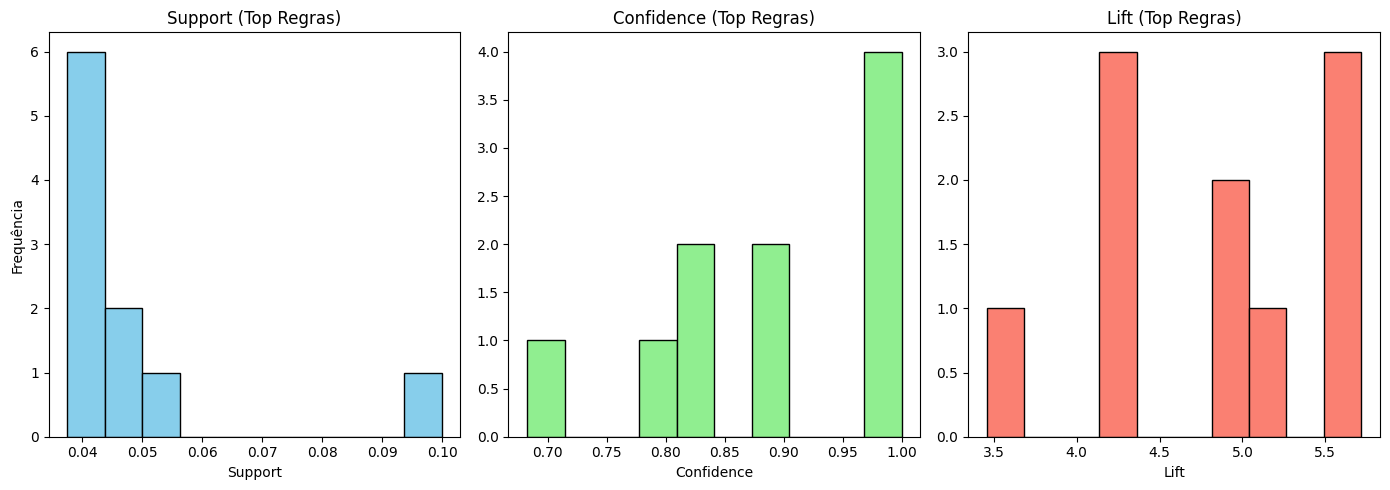

In [19]:
top10 = rules_clean.sort_values('lift', ascending=False).head(10)
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Support
plt.subplot(1, 3, 1)
plt.hist(top10['support'], bins=10, color='skyblue', edgecolor='black')
plt.title('Support (Top Regras)')
plt.xlabel('Support')
plt.ylabel('Frequência')

# Confidence
plt.subplot(1, 3, 2)
plt.hist(top10['confidence'], bins=10, color='lightgreen', edgecolor='black')
plt.title('Confidence (Top Regras)')
plt.xlabel('Confidence')

# Lift
plt.subplot(1, 3, 3)
plt.hist(top10['lift'], bins=10, color='salmon', edgecolor='black')
plt.title('Lift (Top Regras)')
plt.xlabel('Lift')

plt.tight_layout()
plt.show()


O gráfico apresenta três histogramas, um para cada métrica das regras de associação: support, confidence e lift.

Cada histograma mostra quantas regras possuem determinados intervalos de valores. Isto permite perceber
a distribuição das métricas de forma visual:

- **Support:** Mostra quantas regras aparecem frequentemente no dataset. Como o support normalmente é baixo,
  o histograma tende a concentrar muitos valores próximos de zero.

- **Confidence:** Mostra a força das regras. Podemos ver se a maior parte das regras tem confiança baixa,
  média ou alta, e identificar padrões de qualidade.

- **Lift:** Mostra quantas regras têm lift elevado (associações realmente interessantes). Valores altos de lift
  destacam regras raras mas úteis, e o histograma ajuda a perceber se existem muitas ou poucas dessas.

Os histogramas complementam a tabela de estatísticas descritivas, permitindo ver a distribuição real dos valores
e identificar possíveis concentrações, dispersões e outliers nas métricas das regras.


### 6.1 Ajuste de Parâmetros

Para obter regras mais fortes (embora possivelmente em menor quantidade), podemos:

- Reduzir o suporte mínimo dos itemsets;  
- Aumentar a confiança mínima das regras.

A seguir, será testado:
- `min_support = 0.03`  
- `min_confidence = 0.6`


In [8]:
frequent_itemsets2 = apriori(encoded, min_support=0.03, use_colnames=True)
rules2 = association_rules(frequent_itemsets2, metric='confidence', min_threshold=0.6)

# Ordenar por lift para observar as regras mais interessantes
rules_clean = rules2[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
rules_clean.sort_values('lift', ascending=False).head(10)


,antecedents,consequents,support,confidence,lift
81,"(Potential_bin_71-80, Overall_bin_40-60)","(preferred_foot_Right, Age_bin_15-20)",0.037986,0.682683,5.716831
79,"(Potential_bin_71-80, preferred_foot_Right, Ov...",(Age_bin_15-20),0.037986,0.877735,5.680913
57,"(Potential_bin_71-80, Overall_bin_40-60)",(Age_bin_15-20),0.048680,0.874875,5.662402
78,"(Potential_bin_61-70, Age_bin_15-20)","(Overall_bin_40-60, preferred_foot_Right)",0.037485,0.827798,5.158726
56,"(Potential_bin_61-70, Age_bin_15-20)",(Overall_bin_40-60),0.044725,0.987700,5.006540
76,"(Potential_bin_61-70, preferred_foot_Right, Ag...",(Overall_bin_40-60),0.037485,0.986804,5.001996
109,"(Age_bin_31-35, Potential_bin_71-80)","(preferred_foot_Right, Overall_bin_71-80)",0.043611,0.784569,4.293250
70,"(Age_bin_31-35, Potential_bin_71-80)",(Overall_bin_71-80),0.055586,1.000000,4.146420
106,"(Age_bin_31-35, preferred_foot_Right, Potentia...",(Overall_bin_71-80),0.043611,1.000000,4.146420
65,"(Potential_bin_71-80, Age_bin_26-30)",(Overall_bin_71-80),0.099922,0.834031,3.458242


## 6.2 Resultados Finais

Com parâmetros mais exigentes (suporte mais baixo, mas confiança elevada), obtêm-se um conjunto mais reduzido de regras, porém:

- Com **confiança** elevada (probabilidade do consequente dado o antecedente);  
- Com **lift** superior a 1, indicando que a ocorrência conjunta dos itens é mais frequente do que seria esperado ao acaso.

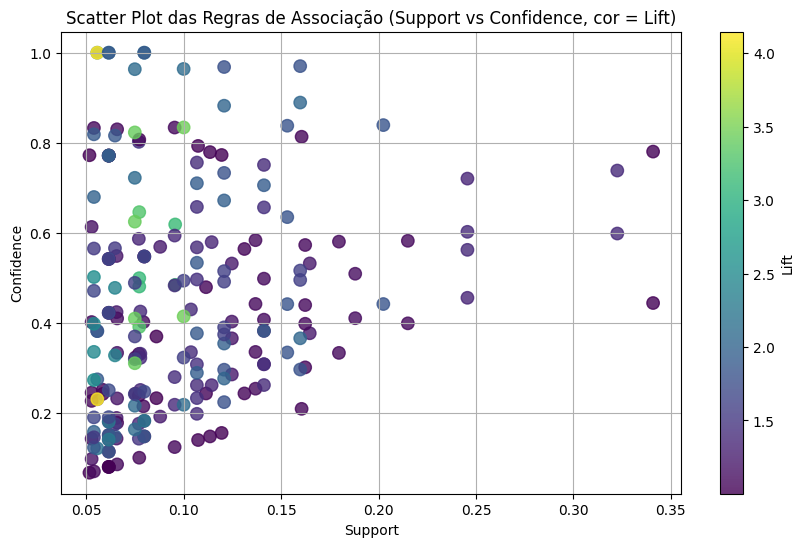

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rules['support'],
    rules['confidence'],
    c=rules['lift'],
    cmap='viridis',
    s=80,
    alpha=0.8
)

plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Scatter Plot das Regras de Associação (Support vs Confidence, cor = Lift)')
plt.grid(True)
plt.show()


### 6.3 Análise do Scatter Plot das Regras de Associação

O gráfico apresentado representa todas as regras de associação geradas pelo algoritmo Apriori, utilizando três métricas fundamentais para avaliar a sua relevância: **support**, **confidence** e **lift**.

- **Support (eixo X)** indica a frequência com que a combinação de itens ocorre no dataset. A maioria das regras apresenta valores de support relativamente baixos, o que é comum em conjuntos de dados com muitas possíveis combinações.
- **Confidence (eixo Y)** representa a probabilidade de o consequente ocorrer quando o antecedente acontece. Observa-se uma grande variação de confiança entre as regras, desde valores muito baixos até valores superiores a 0.9.
- **Lift (cor dos pontos)** mede o quanto a regra é mais forte do que seria esperado ao acaso. Regras com cores mais claras (verde/amarelo) possuem lift mais elevado, enquanto cores mais escuras (roxo/azul) representam lift mais baixo.

A partir do gráfico, é possível identificar que:
- A maioria das regras tem **support baixo**, o que indica que são baseadas em padrões pouco frequentes.
- Existem regras com **confiança elevada**, chegando a valores próximos de 1.0, mostrando forte relação entre os itens envolvidos.
- Apenas um conjunto reduzido de regras apresenta **lift significativamente elevado**, destacando-se como as regras mais interessantes e úteis para interpretação, por revelarem associações não aleatórias.

Este gráfico permite, portanto, uma avaliação visual clara da distribuição e qualidade das regras obtidas, ajudando a identificar quais merecem maior atenção na análise final.


## 7. Conclusão

### 7.1 Avaliação dos Resultados

- As regras de associação extraídas permitem identificar **padrões relevantes** entre atributos dos jogadores FIFA;  
- A discretização de variáveis numéricas (age, overall, potential) foi fundamental para adaptar o dataset ao formato requerido pelo Apriori;  
- A utilização de métricas como **suporte**, **confiança** e **lift** facilitou a seleção das regras mais interessantes.

### 7.2 Lições Aprendidas

- Problemas de regras de associação requerem uma fase de **preparação de dados** cuidadosa (especialmente discretização e one-hot encoding);  
- Pequenas alterações nos parâmetros (`min_support`, `min_confidence`, `min_threshold` para o lift) podem alterar significativamente o conjunto de regras obtidas;  
- A interpretação de regras deve ser feita sempre no contexto do negócio — neste caso, análise de jogadores FIFA.

### 7.3 Continuação do Projeto

Este **Notebook 3 – Association Rules** completa o conjunto de notebooks do Projeto 02, juntando‑se a:

- **Notebook 1 – Classificação Automática**;  
- **Notebook 2 – Clustering**.  

Em conjunto, estes notebooks demonstram a aplicação de diferentes técnicas de **Data Mining** (classificação, clustering e regras de associação) sobre o mesmo dataset, permitindo uma visão mais completa e rica dos dados disponíveis.
